# EXPERIMENT 3 - Feature Selection


In [21]:
import warnings
warnings.filterwarnings('ignore')

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
data =pd.read_excel('Student_placements.xlsx')
data.head()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


In [24]:
new_data =data.drop(columns='College_ID')
new_data.head()

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,107,6.61,6.28,8,No,8,8,4,No
1,97,5.52,5.37,8,No,7,8,0,No
2,109,5.36,5.83,9,No,3,1,1,No
3,122,5.47,5.75,6,Yes,1,6,1,No
4,96,7.91,7.69,7,No,8,10,2,No


In [28]:
convert_col1 ={"Internship_Experience":{"Yes":1, "No":0}}
new_data =new_data.replace(convert_col1)
convert_col2={"Placement":{"Yes":1, "No":0}}
new_data =new_data.replace(convert_col2)
new_data.head()

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,107,6.61,6.28,8,0,8,8,4,0
1,97,5.52,5.37,8,0,7,8,0,0
2,109,5.36,5.83,9,0,3,1,1,0
3,122,5.47,5.75,6,1,1,6,1,0
4,96,7.91,7.69,7,0,8,10,2,0


In [40]:
# checking multicollinearity with variance inflation factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF requires a constant column for the intercept
new_data['intercept'] = 1

# Taking all features in X

X = new_data[['IQ', 'Prev_Sem_Result', 'CGPA', 'Academic_Performance', 'Internship_Experience',
                'Communication_Skills', 'Projects_Completed' , 'Extra_Curricular_Score']]

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
# Drop the placeholder intercept row for final clean view
vif_data = vif_data[vif_data['feature'] != 'intercept']
print(vif_data)


                  feature         VIF
0                      IQ   21.539970
1         Prev_Sem_Result  729.834245
2                    CGPA  715.828193
3    Academic_Performance    4.506545
4   Internship_Experience    1.643807
5    Communication_Skills    4.431443
6      Projects_Completed    3.086369
7  Extra_Curricular_Score    3.384226


In [41]:
#second Method
x= new_data.drop(columns='Placement')
y = new_data['Placement']

In [42]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test=train_test_split(x, y, test_size=0.2,random_state=44, stratify=y)

In [43]:
x_train.shape, x_test. shape

((8000, 9), (2000, 9))

In [44]:
# Selecting K best features
from sklearn.feature_selection import SelectKBest, chi2

In [46]:
x_new = SelectKBest(chi2, k=4).fit_transform(x, y)
x_new

array([[107.  ,   6.28,   8.  ,   4.  ],
       [ 97.  ,   5.37,   8.  ,   0.  ],
       [109.  ,   5.83,   1.  ,   1.  ],
       ...,
       [ 89.  ,   6.25,   9.  ,   5.  ],
       [107.  ,   8.92,   5.  ,   1.  ],
       [109.  ,   9.77,   5.  ,   5.  ]], shape=(10000, 4))

In [47]:
# 3 method 
# Using Gini index for feature importance
from sklearn. tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(criterion='gini')

In [48]:
clf = clf.fit(x_train, y_train)

In [49]:
feature_importances = clf.feature_importances_

Text(0, 0.5, 'Feature')

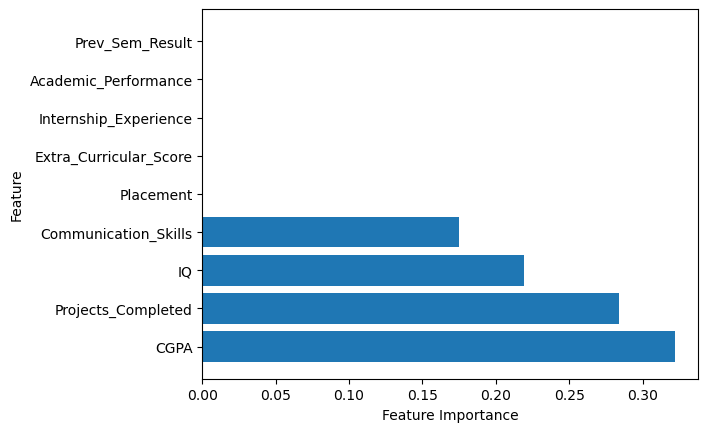

In [50]:
# Sort the feature importances from greatest to least using the sorted indices
sorted_indices = feature_importances.argsort() [ ::- 1]
sorted_feature_names = new_data. columns[sorted_indices]
sorted_importances = feature_importances[sorted_indices]
# Create a bar plot of the feature importances
plt.barh(sorted_feature_names, sorted_importances)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

In [ ]:
#in conclusion ,today we have learned 3 techniques  for feature selection among these 3 techniques we have found 3 most important features are CGPA ,IQ .
#we have have reduced 75 % garbage data and 25% valuable data .
#these techniques are useful for filtering.